In [400]:
import numpy as np
import pandas as pd

In [401]:
rating = pd.read_csv(
    "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/ratings.dat",
    header=None,
    sep='::',
    names=['uid', 'iid', 'rating', 'timestamp'],
    engine='python'
)

item_info = pd.read_csv(
    "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/movies.dat",
    sep='::',
    encoding='latin-1',
    engine='python',
    names=['iid', 'title', 'genres']
)

user_info = pd.read_csv(
    "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/users.dat",
    sep='::',
    encoding='latin-1',
    engine='python',
    names=['uid', 'gender', 'age', 'occupation', 'zipcode']
)

In [402]:
item_info.head()

,iid,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [403]:
user_info.head(2)

,uid,gender,age,occupation,zipcode
0,1,F,1,10,48067
1,2,M,56,16,70072


In [404]:
rating_ = pd.merge(rating,item_info,on='iid',how='inner')

In [405]:
rating_.head(2)

,uid,iid,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical


In [406]:
date_min = pd.to_datetime(rating_.timestamp,unit='s').min() 
date_max = pd.to_datetime(rating_.timestamp,unit='s').max()
date_min,date_max

(Timestamp('2000-04-25 23:05:32'), Timestamp('2003-02-28 17:49:50'))

In [407]:
(date_max.year-date_min.year)*12+date_max.month

38

In [408]:
rating_['time'] = pd.to_datetime(rating_.timestamp,unit='s').map(lambda x: (x.year-date_min.year)*12+x.month)

In [409]:
rating_.head(2)

,uid,iid,rating,timestamp,title,genres,time
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,12
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,12


In [410]:
rating_['time'] = rating_['time'] - rating_['time'].min()

In [411]:
np.sort(rating_.time.unique())

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34])

In [412]:
rating_.head(2)

,uid,iid,rating,timestamp,title,genres,time
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,8
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,8


<Axes: xlabel='time'>

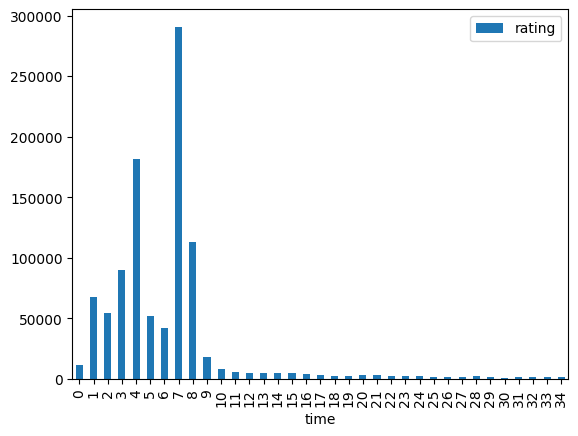

In [413]:
rating_.groupby('time').agg({'rating':'count'}).reset_index().plot(x='time',kind='bar')

In [414]:
rating_.head(2)

,uid,iid,rating,timestamp,title,genres,time
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,8
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,8


In [415]:
train_slot = list(range(14,24))
valid_slot = list(range(24,29))
test_slot = list(range(29,34))

In [416]:
rating_['label'] = rating_['rating'].apply(lambda x: 1 if x>=4 else 0)
rating_.head(5)

,uid,iid,rating,timestamp,title,genres,time,label
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,8,1
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,8,0
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,8,0
3,1,3408,4,978300275,Erin Brockovich (2000),Drama,8,1
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy,9,1


In [417]:
rating_.label.describe()

count    1.000209e+06
mean     5.751608e-01
std      4.943188e-01
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: label, dtype: float64

In [418]:
rating_.uid.min(),rating_.uid.max(),rating_.iid.min(),rating_.iid.max()

(np.int64(1), np.int64(6040), np.int64(1), np.int64(3952))

## split by time order

In [419]:
rating_train = rating_[rating_['time'].isin(train_slot)].copy()
rating_valid = rating_[rating_['time'].isin(valid_slot)].copy()
rating_test = rating_[rating_['time'].isin(test_slot)].copy()

In [420]:
rating_train.shape, rating_valid.shape, rating_test.shape

((33891, 8), (10401, 8), (7331, 8))

In [421]:
rating_valid_f = rating_valid
rating_test_f = rating_test

In [422]:
def filter_cold_start(train,valid,test):
    train_user = train.uid.unique()
    train_item = train.iid.unique()
    valid = valid[valid['uid'].isin(train_user)]
    test = test[test['uid'].isin(train_user)]
    valid = valid[valid['iid'].isin(train_item)]
    test = test[test['iid'].isin(train_item)]
    return valid, test

In [423]:
# rating_valid_f, rating_test_f = filter_cold_start(rating_train,rating_valid,rating_test)
# rating_valid_f.shape, rating_test_f.shape

In [424]:
rating_valid_f.label.mean(), rating_test_f.label.mean() 

(np.float64(0.5283145851360446), np.float64(0.5453553403355613))

In [425]:
rating_valid_f.columns

Index(['uid', 'iid', 'rating', 'timestamp', 'title', 'genres', 'time',
       'label'],
      dtype='object')

In [426]:
import copy
def deal_with_each_u(x,u):
    items = np.array(x.iid)
    labels = np.array(x.label)
    titles = np.array(x.title)
    timestamp = np.array(x.timestamp)
    flags =  np.array(x.flag) 
    his = [0] # adding a '0' by default
    his_title = ['']
    results = []
    for i in range(items.shape[0]):
        results.append((u, items[i], timestamp[i], np.array(his), copy.copy(his_title),titles[i], labels[i], flags[i]))
        # training data
        if labels[i] > 0: # positive 
            his.append(items[i])
            his_title.append(titles[i])
    return results

In [427]:
rating_train = rating_train.copy()

In [428]:
rating_train['flag'] =  pd.DataFrame(np.ones(rating_train.shape[0])*-1, index=rating_train.index)
rating_valid_f['flag'] = pd.DataFrame(np.zeros(rating_valid_f.shape[0]), index=rating_valid_f.index)
rating_test_f['flag'] = pd.DataFrame(np.ones(rating_test_f.shape[0]), index=rating_test_f.index)
data = pd.concat([rating_train, rating_valid_f, rating_test_f],axis=0,ignore_index=True)
data = data.sort_values(by=['uid','timestamp'])
u_inter_all = data.groupby('uid').agg({'iid':list, 'label':list, 'title':list, 'timestamp':list,'flag':list})


In [429]:
data.flag.unique()

array([-1.,  1.,  0.])

In [430]:
results = []
for u in u_inter_all.index:
    results.extend(deal_with_each_u(u_inter_all.loc[u],u))

In [431]:
u_, i_, time_, label_, his_, his_title, title_,flag_ = [],[],[],[],[],[],[],[]
for re_ in results:
    u_.append(re_[0])
    i_.append(re_[1])
    time_.append(re_[2])
    his_.append(re_[3])
    his_title.append(re_[4])
    title_.append(re_[5])
    label_.append(re_[6])
    flag_.append(re_[7])

In [432]:
data = pd.DataFrame({"uid":u_,'iid':i_,'label':label_, 'timestamp': time_ , 'his':his_,'his_title':his_title,'title':title_, 'flag': flag_})


In [433]:
data.head(2)

,uid,iid,label,timestamp,his,his_title,title,flag
0,19,318,1,994556598,[0],[],"Shawshank Redemption, The (1994)",-1.0
1,19,1234,1,994556636,"[0, 318]","[, Shawshank Redemption, The (1994)]","Sting, The (1973)",-1.0


In [434]:
users = data.uid.unique()
items = data.iid.unique()
users_map = dict(zip(users, np.arange(users.shape[0])+1))
items_map = dict(zip(items, np.arange(items.shape[0])+1))

In [435]:
users_map[0]=0
items_map[0]=0

In [436]:
data['uid'] = data['uid'].map(users_map)
data['iid'] = data['iid'].map(items_map)
data.head(2)

,uid,iid,label,timestamp,his,his_title,title,flag
0,1,1,1,994556598,[0],[],"Shawshank Redemption, The (1994)",-1.0
1,1,2,1,994556636,"[0, 318]","[, Shawshank Redemption, The (1994)]","Sting, The (1973)",-1.0


In [437]:
data['his'] = data['his'].apply(lambda x: [items_map[k] for k in x])

In [438]:
data.label.describe()

count    51623.000000
mean         0.536273
std          0.498687
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: label, dtype: float64

In [439]:
data.tail(5)

,uid,iid,label,timestamp,his,his_title,title,flag
51618,838,1619,1,997454429,"[0, 574, 742, 1633, 15, 1894, 1052, 848, 237, ...","[, Dreamlife of Angels, The (La Vie rêvée des ...",Body Heat (1981),-1.0
51619,838,728,1,997454464,"[0, 574, 742, 1633, 15, 1894, 1052, 848, 237, ...","[, Dreamlife of Angels, The (La Vie rêvée des ...",Pi (1998),-1.0
51620,838,407,0,997454464,"[0, 574, 742, 1633, 15, 1894, 1052, 848, 237, ...","[, Dreamlife of Angels, The (La Vie rêvée des ...",As Good As It Gets (1997),-1.0
51621,838,1362,0,997454486,"[0, 574, 742, 1633, 15, 1894, 1052, 848, 237, ...","[, Dreamlife of Angels, The (La Vie rêvée des ...",Crimson Tide (1995),-1.0
51622,838,42,1,998315055,"[0, 574, 742, 1633, 15, 1894, 1052, 848, 237, ...","[, Dreamlife of Angels, The (La Vie rêvée des ...","Godfather: Part II, The (1974)",-1.0


In [440]:
train_ = data[data['flag'].isin([-1])].copy()
valid_ = data[data['flag'].isin([0])].copy()
test_ = data[data['flag'].isin([1])].copy()
train_.shape,valid_.shape,test_.shape

((33891, 8), (10401, 8), (7331, 8))

In [441]:
train_user = train_['uid'].unique()
train_item = train_['iid'].unique()
valid_['not_cold'] = valid_[['uid','iid']].apply(lambda x: x.uid in train_user and x.iid in train_item, axis=1).astype("int")
test_['not_cold'] = test_[['uid','iid']].apply(lambda x: x.uid in train_user and x.iid in train_item, axis=1).astype("int")

In [442]:
train_['not_cold'] = pd.DataFrame(np.ones(train_.shape[0]),index=train_.index).astype("int")
train_.head(2)

,uid,iid,label,timestamp,his,his_title,title,flag,not_cold
0,1,1,1,994556598,[0],[],"Shawshank Redemption, The (1994)",-1.0,1
1,1,2,1,994556636,"[0, 1]","[, Shawshank Redemption, The (1994)]","Sting, The (1973)",-1.0,1


In [443]:
save_path = "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/"
train_.to_pickle(save_path+"train_ood2.pkl")
valid_.to_pickle(save_path+"valid_ood2.pkl")
test_.to_pickle(save_path+"test_ood2.pkl")

In [444]:
valid_small = valid_.sample(frac=0.5,random_state=2023)
valid_small.to_pickle(save_path+"valid_small_ood2.pkl")

In [445]:
valid_small.shape

(5200, 9)

In [446]:
train_['his'].apply(len).describe()

count    33891.000000
mean        38.673866
std         42.590956
min          1.000000
25%          9.000000
50%         23.000000
75%         54.000000
max        339.000000
Name: his, dtype: float64

In [447]:
train_.label.mean(), test_.label.mean(), valid_.label.mean()  

(np.float64(0.5367501696615621),
 np.float64(0.5453553403355613),
 np.float64(0.5283145851360446))

In [448]:
test_.groupby("uid").agg({"label":['count','sum']}).describe()

label            
            count         sum
count  320.000000  320.000000
mean    22.909375   12.493750
std     47.763208   25.020492
min      1.000000    0.000000
25%      3.000000    1.000000
50%      8.000000    4.000000
75%     23.000000   13.000000
max    573.000000  251.000000

In [449]:
train_.groupby("iid").agg({"label":['count','sum']}).describe()

label             
             count          sum
count  3087.000000  3087.000000
mean     10.978620     5.892776
std      12.641559     8.879212
min       1.000000     0.000000
25%       2.000000     1.000000
50%       6.000000     2.000000
75%      15.000000     7.000000
max     154.000000   103.000000

In [450]:
valid_[valid_['uid'].isin(train_['uid'].unique())].uid.unique().shape

(293,)

In [451]:
train_['iid'].unique()

array([   1,    2,    3, ..., 1282, 3254, 3255], shape=(3087,))

In [452]:
valid_[valid_['iid'].isin(train_['iid'].unique())].iid.unique().shape

(2394,)

In [453]:
valid_.iid.unique().shape, test_.iid.unique().shape

((2506,), (2203,))

In [454]:
valid_.uid.unique().shape, test_.uid.unique().shape

((356,), (320,))

In [455]:
train_.uid.unique().shape, train_.iid.unique().shape

((740,), (3087,))

<Axes: xlabel='uid'>

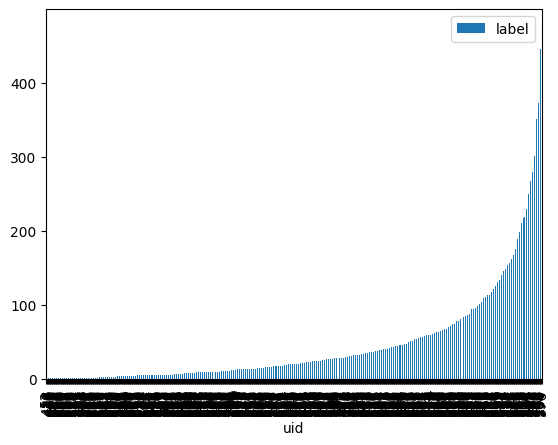

In [456]:
m = train_.groupby('uid').agg({'label':'count'}).sort_values('label').reset_index()
m.plot(x='uid',kind='bar')

In [457]:
train_.uid.max()



np.int64(838)

<Axes: xlabel='uid'>

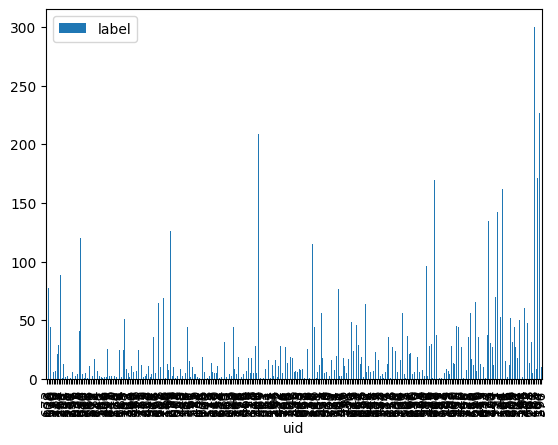

In [458]:
n = valid_.groupby('uid').agg({'label':'count'})
idx = []
a = valid_.uid.unique()
for x in m['uid'].values[:]:
    if x in a:
        idx.append(x)
n.loc[idx].reset_index().plot(x='uid',kind='bar')

<Axes: xlabel='uid'>

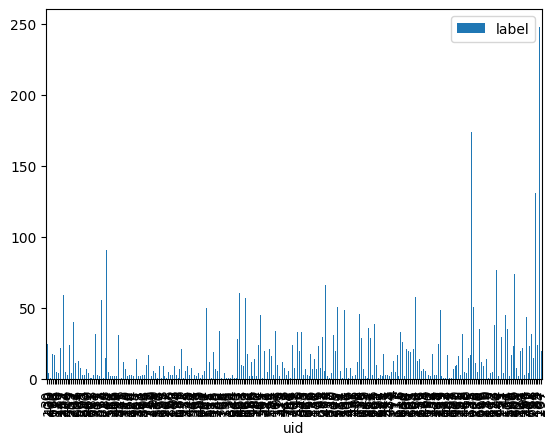

In [459]:
n = test_.groupby('uid').agg({'label':'count'})
idx = []
a = test_.uid.unique()
for x in m['uid'].values[:]:
    if x in a:
        idx.append(x)
n.loc[idx].reset_index().plot(x='uid',kind='bar')

In [460]:
save_path = "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/"
train_ = pd.read_pickle(save_path+"train_ood2.pkl")
valid_ = pd.read_pickle(save_path+"valid_ood2.pkl")
test_ = pd.read_pickle(save_path+"test_ood2.pkl")

In [461]:
max(train_.uid.max(),test_.uid.max(),valid_.uid.max())+1, max(train_.iid.max(),test_.iid.max(),valid_.iid.max())+1


(np.int64(839), np.int64(3256))

In [462]:
valid_small = pd.read_pickle(save_path+"valid_small_ood2.pkl")

In [463]:
valid_small.uid.max(), valid_small.iid.max()

(np.int64(833), np.int64(3249))

In [464]:
import pandas as pd
save_path = "/home/bbx/user_lx/GraphLoRA/dataset/ml-1m/"
# trai.to_pickle(save_path+"train_ood2.pkl")
valid_ = pd.read_pickle(save_path+"valid_ood2.pkl")
test_ = pd.read_pickle(save_path+"test_ood2.pkl")

In [465]:
valid_.not_cold.mean()

np.float64(0.6354196711854629)